# Seconda Milestone Tesi
→ Tutti i risultati devono riportare Accuracy, Macro Averaged Precision, Macro Averaged Recall e Macro Averaged F-Measure.  
→ Tutti i risultati devono riportare il Delay (ossia quanti fotogrammi passano prima che io mi fermi e dia una risposta).  
→ Queste 5 metriche le vorrei vedere su tutte le euristiche, in bar chart (un bar chart per metrica, con 3 barre).  
→ Tutti i risultati devono riportare un intervallo di confidenza.  
  
Produca i 15 risultati per un dataset che utilizza come test set tutti i video di un solo individuo e come training e validation tutti gli altri (divisione LOOCV Leave One Out Cross Validation)

Questo ovviamente va fatto 7 volte, lasciando fuori a turno tutti gli individui, mostrando poi i risultati medi.

## 1 - Importazioni, installazioni e Google Drive

In [1]:
# Installazione librerie
!pip install ultralytics

# Importazioni
import os # Gestione delle directory
from pathlib import Path 	# Individuazione di file e cartelle
import shutil # Copia dei file
from natsort import natsorted # Ordinamento dei fotogrammi
import yaml # Generazione dei file YAML
import ultralytics # Training e inference
import numpy as np # Calcoli numerici
import pandas # Organizzazione dei risultati
import cv2 # Lettura ed elaborazione immagini
import json # Salvataggio delle configurazioni
import math # Libreria matematica generica
import matplotlib.pyplot as plt
from google.colab import drive # Google Drive

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 53.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 2 - Configurazioni e parametri globali

In [2]:
dataset_path = "/content/second-milestone/dataset-originale/"

os.makedirs("/content/second-milestone/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/configurations/", exist_ok=True) # contiene i file di configurazione dei sette fold
os.makedirs("/content/second-milestone/LOOCV/configurations/fold1/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/configurations/fold2/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/configurations/fold3/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/configurations/fold4/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/configurations/fold5/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/configurations/fold6/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/configurations/fold7/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/models/", exist_ok=True) # contiene i pesi dei sette modelli addestrati.
os.makedirs("/content/second-milestone/LOOCV/models/fold1/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/models/fold2/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/models/fold3/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/models/fold4/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/models/fold5/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/models/fold6/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/models/fold7/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/results/", exist_ok=True) # contiene le predizioni e i risultati dei singoli fold
os.makedirs("/content/second-milestone/LOOCV/results/fold1/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/results/fold2/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/results/fold3/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/results/fold4/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/results/fold5/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/results/fold6/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/results/fold7/", exist_ok=True)
os.makedirs("/content/second-milestone/LOOCV/final-results/", exist_ok=True) # contiene le metriche aggregate e i cinque grafici

drive.mount("/content/drive/")

shutil.copy2("/content/drive/MyDrive/tesi/videos-by-people.zip", "/content/second-milestone/videos-by-people.zip")
!unzip -q /content/second-milestone/videos-by-people.zip -d /content/second-milestone/
if os.path.exists("/content/second-milestone/videos-by-people.zip"):
    os.remove("/content/second-milestone/videos-by-people.zip")
os.rename("/content/second-milestone/videos-by-people/", "/content/second-milestone/dataset-originale/") # contiene il dataset originale, senza modifiche

drive.flush_and_unmount()

number_of_participants = 7

Mounted at /content/drive/


## 3 - Analisi e indicizzazione del dataset

In [3]:
original_dataset = Path(dataset_path)

# 1 - Esistono esattamente sette partecipanti?
all_participants = set()
for participant_path in original_dataset.iterdir():
  all_participants.add(participant_path.name)
are_there_exactly_seven_participants = len(all_participants) == 7

# 2 - Ogni video possiede le directory images e labels?
ogni_video_ha_imm_e_lbl = True
for participant_path in original_dataset.iterdir():
  for video_path in participant_path.iterdir():
    images_path = video_path / "images"
    labels_path = video_path / "labels"
    if not (images_path.is_dir() and labels_path.is_dir()):
      ogni_video_ha_imm_e_lbl = False

# 3 - Ogni video possiede un solo file .class?
ogni_video_ha_una_classe = True
for participant_path in original_dataset.iterdir():
  for video_path in participant_path.iterdir():
    class_files = list(video_path.glob('*.class'))
    if not (len(class_files) == 1):
      ogni_video_ha_una_classe = False

# 4 - Il file .class identifica driver oppure passenger?
classi_valide = True
for participant_path in original_dataset.iterdir():
  for video_path in participant_path.iterdir():
    class_files = list(video_path.glob('*.class'))
    for class_file in class_files:
      if class_file.stem not in {"driver", "passenger"}:
        classi_valide = False

# 5 - Ogni video contiene i dieci fotogrammi previsti?
esattamente_dieci_foto = True
for participant_path in original_dataset.iterdir():
  for video_path in participant_path.iterdir():
    images_path = video_path / "images"
    images_num = 0
    for image_path in images_path.iterdir():
      images_num += 1
    if images_num != 10:
      esattamente_dieci_foto = False

# 6 - Ogni immagine possiede la propria annotazione?
ogni_img_ha_ann = True
for participant_path in original_dataset.iterdir():
  for video_path in participant_path.iterdir():
    images_path = video_path / "images"
    labels_path = video_path / "labels"
    for image_path in images_path.iterdir():
      if image_path.is_file() and image_path.suffix.lower() == ".jpg":
        label_path = labels_path / f"{image_path.stem}.txt"
        if not label_path.is_file():
          ogni_img_ha_ann = False

# 7 - Gli ID delle annotazioni sono compresi tra 0 e 6?
id_compresi_0_6 = True
for participant_path in original_dataset.iterdir():
  for video_path in participant_path.iterdir():
    labels_path = video_path / "labels"
    for label_path in labels_path.iterdir():
      if label_path.is_file() and label_path.suffix.lower() == ".txt":
        with label_path.open('r', encoding='utf-8') as f:
          first_chars = [line[0] for line in f if line.strip()]
        for ch in first_chars:
          if not (0 <= int(ch) and int(ch) <= 6):
            id_compresi_0_6 = False

print(f"1 - Esistono esattamente sette partecipanti? -> {"Sì" if are_there_exactly_seven_participants else "No"}")
print(f"2 - Ogni video possiede le directory images e labels? -> {"Sì" if ogni_video_ha_imm_e_lbl else "No"}")
print(f"3 - Ogni video possiede un solo file .class? -> {"Sì" if ogni_video_ha_una_classe else "No"}")
print(f"4 - Il file .class identifica driver oppure passenger? -> {"Sì" if classi_valide else "No"}")
print(f"5 - Ogni video contiene i dieci fotogrammi previsti? -> {"Sì" if esattamente_dieci_foto else "No"}")
print(f"6 - Ogni immagine possiede la propria annotazione? -> {"Sì" if ogni_img_ha_ann else "No"}")
print(f"7 - Gli ID delle annotazioni sono compresi tra 0 e 6? -> {"Sì" if id_compresi_0_6 else "No"}")

1 - Esistono esattamente sette partecipanti? -> Sì
2 - Ogni video possiede le directory images e labels? -> Sì
3 - Ogni video possiede un solo file .class? -> Sì
4 - Il file .class identifica driver oppure passenger? -> Sì
5 - Ogni video contiene i dieci fotogrammi previsti? -> Sì
6 - Ogni immagine possiede la propria annotazione? -> Sì
7 - Gli ID delle annotazioni sono compresi tra 0 e 6? -> Sì


In [4]:
# Lista di dizionari dei video
videos_index = []

original_dataset = Path(dataset_path)
for elem in original_dataset.iterdir():
  if elem.is_dir():
    for elem2 in elem.iterdir():
      if elem2.is_dir():
        video_dictionary = {}
        frames_number = 0
        video_dictionary["Partecipante"] = elem.name
        video_dictionary["Nome video"] = elem2.name
        video_dictionary["Directory del video"] = str(elem2.resolve())
        for elem3 in elem2.iterdir():
          if elem3.is_dir():
            if elem3.name == "images":
              video_dictionary["Directory immagini"] = str(elem3.resolve())
              for elem4 in elem3.iterdir():
                if elem4.is_file():
                  if elem4.suffix.lower() == ".jpg":
                    frames_number += 1
            elif elem3.name == "labels":
              video_dictionary["Directory annotazioni"] = str(elem3.resolve())
          elif elem3.is_file():
            if elem3.suffix.lower() == ".class":
              video_dictionary["Classe reale"] = elem3.stem
        video_dictionary["Numero fotogrammi"] = frames_number
        videos_index.append(video_dictionary)

In [5]:
videos_dataframe = pandas.DataFrame(videos_index)
videos_dataframe

,Partecipante,Nome video,Directory del video,Directory immagini,Classe reale,Directory annotazioni,Numero fotogrammi
0,set7,set7-frontpassenger-night-obj-similarcolor,/content/second-milestone/dataset-originale/se...,/content/second-milestone/dataset-originale/se...,passenger,/content/second-milestone/dataset-originale/se...,10
1,set7,set7-frontpassenger-night-nobj-similarcolor,/content/second-milestone/dataset-originale/se...,/content/second-milestone/dataset-originale/se...,passenger,/content/second-milestone/dataset-originale/se...,10
2,set7,set7-backleftpassenger-night-obj-differentcolor,/content/second-milestone/dataset-originale/se...,/content/second-milestone/dataset-originale/se...,passenger,/content/second-milestone/dataset-originale/se...,10
3,set7,set7-driver-day-nobj-differentcolor,/content/second-milestone/dataset-originale/se...,/content/second-milestone/dataset-originale/se...,driver,/content/second-milestone/dataset-originale/se...,10
4,set7,set7-frontpassenger-day-nobj-differentcolor,/content/second-milestone/dataset-originale/se...,/content/second-milestone/dataset-originale/se...,passenger,/content/second-milestone/dataset-originale/se...,10
...,...,...,...,...,...,...,...
187,set4,set4-frontpassenger-day-obj-similarcolor,/content/second-milestone/dataset-originale/se...,/content/second-milestone/dataset-originale/se...,passenger,/content/second-milestone/dataset-originale/se...,10
188,set4,set4-backrightpassenger-day-obj-similarcolor,/content/second-milestone/dataset-originale/se...,/content/second-milestone/dataset-originale/se...,passenger,/content/second-milestone/dataset-originale/se...,10
189,set4,set4-frontpassenger-night-nobj-differentcolor,/content/second-milestone/dataset-originale/se...,/content/second-milestone/dataset-originale/se...,passenger,/content/second-milestone/dataset-originale/se...,10
190,set4,set4-frontpassenger-night-nobj-similarcolor,/content/second-milestone/dataset-originale/se...,/content/second-milestone/dataset-originale/se...,passenger,/content/second-milestone/dataset-originale/se...,10


In [6]:
sets_index = [
    {"Partecipante": "set1", "Video": 0, "Fotogrammi": 0},
    {"Partecipante": "set2", "Video": 0, "Fotogrammi": 0},
    {"Partecipante": "set3", "Video": 0, "Fotogrammi": 0},
    {"Partecipante": "set4", "Video": 0, "Fotogrammi": 0},
    {"Partecipante": "set5", "Video": 0, "Fotogrammi": 0},
    {"Partecipante": "set6", "Video": 0, "Fotogrammi": 0},
    {"Partecipante": "set7", "Video": 0, "Fotogrammi": 0},
]

for video in videos_index:
  if video["Partecipante"] == "set1":
    sets_index[0]["Video"] += 1
    sets_index[0]["Fotogrammi"] += 10
  elif video["Partecipante"] == "set2":
    sets_index[1]["Video"] += 1
    sets_index[1]["Fotogrammi"] += 10
  elif video["Partecipante"] == "set3":
    sets_index[2]["Video"] += 1
    sets_index[2]["Fotogrammi"] += 10
  elif video["Partecipante"] == "set4":
    sets_index[3]["Video"] += 1
    sets_index[3]["Fotogrammi"] += 10
  elif video["Partecipante"] == "set5":
    sets_index[4]["Video"] += 1
    sets_index[4]["Fotogrammi"] += 10
  elif video["Partecipante"] == "set6":
    sets_index[5]["Video"] += 1
    sets_index[5]["Fotogrammi"] += 10
  elif video["Partecipante"] == "set7":
    sets_index[6]["Video"] += 1
    sets_index[6]["Fotogrammi"] += 10

sets_dataframe = pandas.DataFrame(sets_index)
sets_dataframe

,Partecipante,Video,Fotogrammi
0,set1,32,320
1,set2,32,320
2,set3,16,160
3,set4,32,320
4,set5,32,320
5,set6,16,160
6,set7,32,320


## 4 - 	Generazione dei sette fold

In [7]:
sets_videos_paths = {
    "set1": [],
    "set2": [],
    "set3": [],
    "set4": [],
    "set5": [],
    "set6": [],
    "set7": []
}

for video in videos_index:
  sets_videos_paths[video["Partecipante"]].append(video["Directory immagini"])

folds_dictionary = {
    "fold1": {
        "Training": {"set3": sets_videos_paths["set3"], "set4": sets_videos_paths["set4"], "set5": sets_videos_paths["set5"], "set6": sets_videos_paths["set6"], "set7": sets_videos_paths["set7"]},
        "Validation": {"set2": sets_videos_paths["set2"]},
        "Test": {"set1": sets_videos_paths["set1"]}
    },
    "fold2": {
        "Training": {"set1": sets_videos_paths["set1"], "set4": sets_videos_paths["set4"], "set5": sets_videos_paths["set5"], "set6": sets_videos_paths["set6"], "set7": sets_videos_paths["set7"]},
        "Validation": {"set3": sets_videos_paths["set3"]},
        "Test": {"set2": sets_videos_paths["set2"]}
    },
    "fold3": {
        "Training": {"set1": sets_videos_paths["set1"], "set2": sets_videos_paths["set2"], "set5": sets_videos_paths["set5"], "set6": sets_videos_paths["set6"], "set7": sets_videos_paths["set7"]},
        "Validation": {"set4": sets_videos_paths["set4"]},
        "Test": {"set3": sets_videos_paths["set3"]}
    },
    "fold4": {
        "Training": {"set1": sets_videos_paths["set1"], "set2": sets_videos_paths["set2"], "set3": sets_videos_paths["set3"], "set6": sets_videos_paths["set6"], "set7": sets_videos_paths["set7"]},
        "Validation": {"set5": sets_videos_paths["set5"]},
        "Test": {"set4": sets_videos_paths["set4"]}
    },
    "fold5": {
        "Training": {"set1": sets_videos_paths["set1"], "set2": sets_videos_paths["set2"], "set3": sets_videos_paths["set3"], "set4": sets_videos_paths["set4"], "set7": sets_videos_paths["set7"]},
        "Validation": {"set6": sets_videos_paths["set6"]},
        "Test": {"set5": sets_videos_paths["set5"]}
    },
    "fold6": {
        "Training": {"set1": sets_videos_paths["set1"], "set2": sets_videos_paths["set2"], "set3": sets_videos_paths["set3"], "set4": sets_videos_paths["set4"], "set5": sets_videos_paths["set5"]},
        "Validation": {"set7": sets_videos_paths["set7"]},
        "Test": {"set6": sets_videos_paths["set6"]}
    },
    "fold7": {
        "Training": {"set2": sets_videos_paths["set2"], "set3": sets_videos_paths["set3"], "set4": sets_videos_paths["set4"], "set5": sets_videos_paths["set5"], "set6": sets_videos_paths["set6"]},
        "Validation": {"set1": sets_videos_paths["set1"]},
        "Test": {"set7": sets_videos_paths["set7"]}
    }
}

folds_dataframe = pandas.DataFrame.from_dict(folds_dictionary, orient="index")
folds_dataframe

,Training,Validation,Test
fold1,{'set3': ['/content/second-milestone/dataset-o...,{'set2': ['/content/second-milestone/dataset-o...,{'set1': ['/content/second-milestone/dataset-o...
fold2,{'set1': ['/content/second-milestone/dataset-o...,{'set3': ['/content/second-milestone/dataset-o...,{'set2': ['/content/second-milestone/dataset-o...
fold3,{'set1': ['/content/second-milestone/dataset-o...,{'set4': ['/content/second-milestone/dataset-o...,{'set3': ['/content/second-milestone/dataset-o...
fold4,{'set1': ['/content/second-milestone/dataset-o...,{'set5': ['/content/second-milestone/dataset-o...,{'set4': ['/content/second-milestone/dataset-o...
fold5,{'set1': ['/content/second-milestone/dataset-o...,{'set6': ['/content/second-milestone/dataset-o...,{'set5': ['/content/second-milestone/dataset-o...
fold6,{'set1': ['/content/second-milestone/dataset-o...,{'set7': ['/content/second-milestone/dataset-o...,{'set6': ['/content/second-milestone/dataset-o...
fold7,{'set2': ['/content/second-milestone/dataset-o...,{'set1': ['/content/second-milestone/dataset-o...,{'set7': ['/content/second-milestone/dataset-o...


In [8]:
for fold_idx in range(1, 8):
  is_participant_in_only_one_set = True
  each_video_assigned_one_time_only_to_a_set = True

  fold_dict = folds_dictionary[f"fold{fold_idx}"]

  num_participants_in_training = 0
  for key in fold_dict["Training"].keys():
    num_participants_in_training += 1
  if num_participants_in_training != 5:
    raise Exception(f"ERRORE: Il numero di partecipanti in training in fold{fold_idx} non è pari a 5!")

  num_participants_in_validation = 0
  for key in fold_dict["Validation"].keys():
    num_participants_in_validation += 1
  if num_participants_in_validation != 1:
    raise Exception(f"ERRORE: Il numero di partecipanti in validation in fold{fold_idx} non è pari a 1!")

  num_participants_in_test = 0
  for key in fold_dict["Test"].keys():
    num_participants_in_test += 1
  if num_participants_in_test != 1:
    raise Exception(f"ERRORE: Il numero di partecipanti in test in fold{fold_idx} non è pari a 1!")

  participants_list = ["set1", "set2", "set3", "set4", "set5", "set6", "set7"]

  for participant in participants_list:
    is_participant_in_train = participant in fold_dict["Training"]
    is_participant_in_val = participant in fold_dict["Validation"]
    is_participant_in_test = participant in fold_dict["Test"]
    if (is_participant_in_train + is_participant_in_val + is_participant_in_test) != 1:
      raise Exception(f"ERRORE: In fold{fold_idx} non è vero che ogni partecipante è presente in uno e un solo insieme!")

  for video in videos_index:
    all_training_video_images_paths = []
    all_validation_video_images_paths = []
    all_test_video_images_paths = []
    for key in fold_dict["Training"]:
      all_training_video_images_paths.extend(fold_dict["Training"][key])
    for key in fold_dict["Validation"]:
      all_validation_video_images_paths.extend(fold_dict["Validation"][key])
    for key in fold_dict["Test"]:
      all_test_video_images_paths.extend(fold_dict["Test"][key])
    is_video_in_train = video['Directory immagini'] in all_training_video_images_paths
    is_video_in_validation = video['Directory immagini'] in all_validation_video_images_paths
    is_video_in_test = video['Directory immagini'] in all_test_video_images_paths
    if (is_video_in_train + is_video_in_validation + is_video_in_test) != 1:
       raise Exception(f"ERRORE: In fold{fold_idx} non è vero che ogni video è presente in uno e un solo insieme tra train, val e test!")

print("Il controllo di integrità è stato eseguito con successo!")

Il controllo di integrità è stato eseguito con successo!


## 5 - Generazione dei dataset per YOLOv8

In [9]:
configurations_path = Path("/content/second-milestone/LOOCV/configurations/")

for elem in configurations_path.iterdir():
  if elem.is_dir():
    train_file_path = elem.resolve() / "train.txt"
    val_file_path = elem.resolve() / "val.txt"
    data_file_path = elem.resolve() / "data.yaml"

    with train_file_path.open("w", encoding="utf-8") as file:
      for key in folds_dictionary[elem.name]["Training"].keys():
        for images_path_str in folds_dictionary[elem.name]["Training"][key]:
          images_path = Path(images_path_str)
          for image_path in images_path.iterdir():
            file.write(f"{image_path.resolve()}\n")

    with val_file_path.open("w", encoding="utf-8") as file:
      for key in folds_dictionary[elem.name]["Validation"].keys():
        for images_path_str in folds_dictionary[elem.name]["Validation"][key]:
          images_path = Path(images_path_str)
          for image_path in images_path.iterdir():
            file.write(f"{image_path.resolve()}\n")

    with data_file_path.open("w", encoding="utf-8") as file:
      file.write(f"path: {dataset_path}\n\n")
      file.write(f"train: {train_file_path.resolve()}\n\n")
      file.write(f"val: {val_file_path.resolve()}\n\n")
      file.write("names:\n")
      file.write("  0: driver-seat-belt\n")
      file.write("  1: driver-sun-visor\n")
      file.write("  2: driver-window\n")
      file.write("  3: passenger-grab-handle\n")
      file.write("  4: passenger-seat-belt\n")
      file.write("  5: passenger-sun-visor\n")
      file.write("  6: passenger-window\n")

In [10]:
configurations_path = Path("/content/second-milestone/LOOCV/configurations/")

for fold_config_path in configurations_path.iterdir():
    if not fold_config_path.is_dir():
        continue
    fold_dict = folds_dictionary[fold_config_path.name]

    data_file_path = fold_config_path / "data.yaml"

    # 1 - Che train.txt contenga esclusivamente i cinque partecipanti del training.
    train_file_path = fold_config_path / "train.txt"
    training_participants = set(fold_dict["Training"].keys())
    with train_file_path.open(mode="r", encoding="utf-8") as file:
      participants = set()
      for line in file:
          clean_line = line.rstrip("\n")
          if not clean_line:
              continue
          path = Path(clean_line)
          participants.add(path.parts[4])
          # 3 - Che ogni immagine abbia la relativa annotazione.
          label_path = path.parent.parent / "labels" / f"{path.stem}.txt"
          if not label_path.is_file():
            raise Exception(f"ERRORE: Una immagine in {fold_config_path.name} non ha la relativa annotazione!")
          # 4 - Che le annotazioni utilizzino il formato YOLO corretto.
          with label_path.open(mode="r", encoding="utf-8") as file:
            for line in file:
              clean_line = line.rstrip("\n")
              clean_line_parts = clean_line.split()
              if len(clean_line_parts) != 5:
                raise Exception(f"ERRORE: Non è vero che in {fold_config_path.name} le annotazioni utilizzano il formato YOLO corretto!")
              for i in range(len(clean_line_parts)):
                # 5 - Che gli ID numerici delle classi corrispondano esattamente ai nomi definiti in data.yaml.
                if i == 0:
                  with data_file_path.open("r", encoding="utf-8") as f:
                    data = yaml.safe_load(f)
                  names = data["names"]
                  if isinstance(names, dict):
                    class_indexes = list(names.keys())
                  elif isinstance(names, list):
                    class_indexes = list(range(len(names)))
                  if int(clean_line_parts[i]) not in class_indexes:
                    raise Exception(f"Non è vero che in {fold_config_path.name} gli ID numerici delle classi corrispondono esattamente ai nomi definiti in data.yaml.")
                elif i > 0:
                  value = float(clean_line_parts[i])
                  if not (0.0 <= value <= 1.1):
                    raise Exception(f"ERRORE: Non è vero che in {fold_config_path.name} le annotazioni utilizzano il formato YOLO corretto!")
      if training_participants != participants:
        raise Exception(f"ERRORE: Non è vero che in {fold_config_path.name} train.txt contiene esclusivamente i cinque partecipanti del training!")

    # 2 - Che val.txt contenga esclusivamente il partecipante della validation.
    val_file_path = fold_config_path / "val.txt"
    val_participants = set(fold_dict["Validation"].keys())
    with val_file_path.open(mode="r", encoding="utf-8") as file:
      participants = set()
      for line in file:
          clean_line = line.rstrip("\n")
          if not clean_line:
              continue
          path = Path(clean_line)
          participants.add(path.parts[4])
          # 3 - Che ogni immagine abbia la relativa annotazione.
          label_path = path.parent.parent / "labels" / f"{path.stem}.txt"
          if not label_path.is_file():
            raise Exception(f"ERRORE: Una immagine in {fold_config_path.name} non ha la relativa annotazione!")
          # 4 - Che le annotazioni utilizzino il formato YOLO corretto.
          with label_path.open(mode="r", encoding="utf-8") as file:
            for line in file:
              clean_line = line.rstrip("\n")
              clean_line_parts = clean_line.split()
              if len(clean_line_parts) != 5:
                raise Exception(f"ERRORE: Non è vero che in {fold_config_path.name} le annotazioni utilizzano il formato YOLO corretto!")
              for i in range(len(clean_line_parts)):
                # 5 - Che gli ID numerici delle classi corrispondano esattamente ai nomi definiti in data.yaml.
                if i == 0:
                  with data_file_path.open("r", encoding="utf-8") as f:
                    data = yaml.safe_load(f)
                  names = data["names"]
                  if isinstance(names, dict):
                    class_indexes = list(names.keys())
                  elif isinstance(names, list):
                    class_indexes = list(range(len(names)))
                  if int(clean_line_parts[i]) not in class_indexes:
                    raise Exception(f"Non è vero che in {fold_config_path.name} gli ID numerici delle classi corrispondono esattamente ai nomi definiti in data.yaml.")
                elif i > 0:
                  value = float(clean_line_parts[i])
                  if not (0.0 <= value <= 1.1):
                    raise Exception(f"ERRORE: Non è vero che in {fold_config_path.name} le annotazioni utilizzano il formato YOLO corretto!")
      if val_participants != participants:
        raise Exception(f"ERRORE: Non è vero che in {fold_config_path.name} val.txt contiene esclusivamente il singolo partecipante della validation!")

print("Controllo di integrità eseguito con successo!")

Controllo di integrità eseguito con successo!


## 6 - Training dei sette modelli

In [11]:
# Iperparametri
initial_model = "yolov8s.pt"
epochs = 200
batch = 16
patience = 50
image_size = 640
mosaic = 0.0
cls = 1.5
plots = True
name = "train"
exist_ok = True
seed = 42
project = "/content/second-milestone/LOOCV/models/"

configurations_path = Path("/content/second-milestone/LOOCV/configurations/")

for fold_configuration in configurations_path.iterdir():
  data_file_path = fold_configuration.resolve() / "data.yaml"
  model = ultralytics.YOLO(initial_model)
  results = model.train(
    data=str(data_file_path.resolve()),
    epochs=epochs,
    batch=batch,
    patience=patience,
    imgsz=image_size,
    plots=plots,
    exist_ok=exist_ok,
    mosaic=mosaic,
    cls=cls,
    seed=seed,
    project=project,
    name=fold_configuration.name
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=1.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/second-milestone/LOOCV/configurations/fold5/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=fold5, nbs=64, nms=None, 

## 7 - Inference e applicazione delle euristiche

In [12]:
baseline_name = "baseline"
MCS_name = "MCS"
MCSwT_name = "MCSwT"
# Variabile per abilitare o disabilitare il comportamento degli oggetti speciali
special = "special"

# Definisce la dimensione delle immagini in pixel (larghezza)
TRAINING_WIDTH = 640
# Definisce la dimensione delle immagini in pixel (altezza)
TRAINING_HEIGHT = 640

# Imposta la soglia di confidenza minima richiesta per convalidare il rilevamento di oggetti speciali
SPECIAL_OBJ_TRESHOLD = 0.8

special_objects_names = ["passenger-grab-handle"]

heuristics = [ baseline_name, MCS_name, MCSwT_name ]

# Definisce la dimensione fissa della finestra temporale dei frame da analizzare
window_size = 3

# Imposta il numero minimo di finestre da analizzare prima di iniziare a monitorare ed esportare le metriche
start_recording_window = 2

In [13]:
# Ritorna la classe dell'oggetto speciale se presente (per classificarlo senza utilizzare alcuna euristica), altrimenti None
# questa funzione è utile per evitare di classificare il frame con un euristica sapendo che un determinato oggetto è caratterizzante di una classe (e.g. passenger-grab-handle)
def has_special_object(X, results, conf_treshold = 0.7, special_objects_names = []):
  # Se l'analisi degli oggetti speciali è disattivata, ritorna immediatamente None
  if special == "nospecial":
    # Ritorna None
    return None
  # Inizializza l'indice per scorrere i risultati
  index = 0
  # Itera su ciascun risultato di rilevamento
  for r in results:
    # Itera sugli indici delle bounding box rilevate
    for index in range(0, len(r.boxes.cls)):
      # Itera sulla lista dei nomi degli oggetti speciali da cercare
      for special_object in special_objects_names:
        # Controlla se l'oggetto speciale corrisponde al nome della classe corrente con confidenza superiore alla soglia
        if special_object in X[int(r.boxes.cls[index])] and float(r.boxes.conf[index]) > conf_treshold:
          # Se l'oggetto appartiene alla classe passeggero, ritorna la stringa passenger
          if "passenger" in special_object:
            # Ritorna passenger
            return "passenger"
          # Altrimenti, se l'oggetto appartiene alla classe conducente, ritorna driver
          elif "driver" in special_object:
            # Ritorna driver
            return "driver"
  # Se nessun oggetto speciale soddisfa i criteri, ritorna None
  return None

In [14]:
# Definizione della funzione baseline che classifica il frame contando semplicemente la cardinalità delle bounding box rilevate
def baseline(results, special_objects_names):
  # Numero di bounding box di oggetti della classe driver riconosciuti nel frame corrente dal modello
  driver_class_bb_cardinality = 0
  # Numero di bounding box di oggetti della classe passenger riconosciuti nel frame corrente dal modello
  passenger_class_bb_cardinality = 0

  # Iteriamo sui risultati restituiti dal modello YOLO per analizzare le classi dei box predetti
  for r in results:
    for c in r.boxes.cls:
      # si noti che basta controllare se la classe è contenuta come sottostringa (e.g. driver-window, driver-seat-belt, driver-handle, etc),
      if "driver" in X[int(c)]:
        driver_class_bb_cardinality += 1
      elif "passenger" in X[int(c)]:
        passenger_class_bb_cardinality += 1
  # classifichiamo il frame confrontando le due cardinalità calcolate
  if driver_class_bb_cardinality > passenger_class_bb_cardinality:
    return "driver"
  elif passenger_class_bb_cardinality > driver_class_bb_cardinality:
    return "passenger"
  else:
    return "none"

In [15]:
# Calcola la somma dei valori di confidenza per le classi driver e passenger
def compute_sum_confidence(X_k, results):
  # Inizializza la somma della confidenza per la classe driver
  driver_bb_conf = 0
  # Inizializza la somma della confidenza per la classe passenger
  passenger_bb_conf = 0

  # Inizializza l'indice per tracciare le corrispondenze
  index = 0
  # Scorre tutti i risultati restituiti dal modello
  for r in results:
    # Scorre le confidenze associate a ciascuna bounding box
    for c in r.boxes.conf:
      # Se la classe dell'oggetto contiene la parola driver, somma la confidenza
      if "driver" in X_k[index]:
        # Incrementa la confidenza cumulativa per il conducente
        driver_bb_conf += float(c)
      # Altrimenti se contiene la parola passenger, somma la confidenza
      elif "passenger" in X_k[index]:
        # Incrementa la confidenza cumulativa per il passeggero
        passenger_bb_conf += float(c)
      # Incrementa l'indice della bounding box sotto esame
      index += 1
  # Ritorna la tupla contenente la confidenza del conducente e del passeggero
  return (driver_bb_conf, passenger_bb_conf)

In [16]:
# Computa il multiinsieme X_k contenente elementi in X che compaiono nell'immagine k
def compute_X_k(X, results):
  # Inizializza una lista vuota per contenere i nomi delle classi rilevate
  X_k = []
  # Itera sui risultati per estrarre le classi
  for r in results:
    # Popoliamo X_k con le etichette testuali delle classi
    for c in r.boxes.cls:
      # Aggiunge alla lista il nome della classe corrispondente
      X_k.append(X[int(c)])
  # Ritorna la lista dei nomi delle classi rilevate
  return X_k

In [17]:
# Esegue la classificazione MCS confrontando la somma delle confidenze delle classi
def MCS(results, special_objects_names):
  # Estrae la lista delle classi rilevate nel frame
  X_k = compute_X_k(X, results)
  # Calcola la somma dei punteggi di confidenza per conducente e passeggero
  driver_bb_conf, passenger_bb_conf = compute_sum_confidence(X_k, results)

  # Confronta i punteggi per classificare il frame
  if driver_bb_conf > passenger_bb_conf:
    # Ritorna driver
    return "driver"
  # Se la confidenza del passeggero è maggiore di quella del conducente
  elif passenger_bb_conf > driver_bb_conf:
    # Ritorna passenger
    return "passenger"
  # Se i punteggi sono identici o non ci sono rilevamenti
  else:
    # Ritorna none
    return "none"

In [18]:
# Esegue la classificazione MCS con soglia di attivazione per discriminare i casi dubbi
def MCS_with_treshold_activation(results, special_objects_names, T=0.4):
  # Estrae la lista delle classi rilevate nel frame
  X_k = compute_X_k(X, results)
  # Calcola le somme delle confidenze per conducente e passeggero
  driver_bb_conf, passenger_bb_conf = compute_sum_confidence(X_k, results)

  # Verifica se la differenza assoluta tra i punteggi è superiore alla soglia T
  if (abs(driver_bb_conf - passenger_bb_conf) > T):
    # Confronta direttamente le somme per decidere la classe
    if driver_bb_conf > passenger_bb_conf:
      # Ritorna driver
      return "driver"
    # Se la confidenza del passeggero è maggiore
    elif passenger_bb_conf > driver_bb_conf:
      # Ritorna passenger
      return "passenger"
    # In caso di parità
    else:
      # Ritorna none
      return "none"
  # Se la differenza non supera la soglia, ripiega sul metodo baseline
  else:
    # Chiama e ritorna il risultato della funzione baseline
    return baseline(results, special_objects_names)

In [19]:
def get_window_classifications(frame_classifications, heuristics, current_frame, window_size):
  window_driver_classifications = {}
  window_driver_classifications[baseline_name] = 0
  window_driver_classifications[MCS_name] = 0
  window_driver_classifications[MCSwT_name] = 0

  window_passenger_classifications = {}
  window_passenger_classifications[baseline_name] = 0
  window_passenger_classifications[MCS_name] = 0
  window_passenger_classifications[MCSwT_name] = 0

  for counter in range(0, window_size):
    for heuristic in heuristics:
      val = frame_classifications[heuristic][current_frame - counter]
      if val == "driver":
        window_driver_classifications[heuristic] += 1
      elif val == "passenger":
        window_passenger_classifications[heuristic] += 1

  return (window_driver_classifications, window_passenger_classifications)

In [20]:
def update_classifications(window_driver_classifications, driver_frames, window_passenger_classifications, passenger_frames, heuristics, none_frames):
  for heuristic in heuristics:
    # Applichiamo la politica per la classificazione del frame in osservazione tenendo in considerazione la finestra di frame precedenti
    if window_driver_classifications[heuristic] > window_passenger_classifications[heuristic]:
      # aggiorniamo i frame classificati come "driver"
      driver_frames[heuristic] += 1
    elif window_passenger_classifications[heuristic] > window_driver_classifications[heuristic]:
      # aggiorniamo i frame classificati como "passenger"
      passenger_frames[heuristic] += 1
    else:
      none_frames[heuristic] += 1
  return (driver_frames, passenger_frames, none_frames)

In [21]:
def compute_video_class(driver_frames, passenger_frames, heuristics):
  preds = {}
  for heuristic in heuristics:
    if driver_frames[heuristic] > passenger_frames[heuristic]:
      preds[heuristic] = "driver"
    elif passenger_frames[heuristic] > driver_frames[heuristic]:
      preds[heuristic] = "passenger"
    else:
      preds[heuristic] = "none"
  return preds

In [22]:
def get_classification_confidence(driver_frames, passenger_frames, heuristics, window_counter):
  accuracy = {}
  for heuristic in heuristics:
    maximum_predictions_class = "passenger" if passenger_frames[heuristic] > driver_frames[heuristic] else "driver"
    if maximum_predictions_class == "passenger":
      accuracy[heuristic] = passenger_frames[heuristic] / window_counter
    elif maximum_predictions_class == "driver":
      accuracy[heuristic] = driver_frames[heuristic] / window_counter
  return accuracy

In [23]:
def predict_on_one_video(video_directory, model, X, fps, total_frames, classification_confidence_list = [0.4, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99], start_recording_window = 2):
  print(f"Predict on: {video_directory}")
  window_counter = 0

  frame_accuracy = {}
  for k in range(0, len(classification_confidence_list)):
    frame_accuracy[k] = {}

  fails = {}
  for k in range (0, len(classification_confidence_list)):
    fails[k] = {}

  real_video_class = Path(next(Path(video_directory).parent.glob("*.class"), None)).stem

  driver_frames = {}
  driver_frames[baseline_name] = 0
  driver_frames[MCS_name] = 0
  driver_frames[MCSwT_name] = 0

  passenger_frames = {}
  passenger_frames[baseline_name] = 0
  passenger_frames[MCS_name] = 0
  passenger_frames[MCSwT_name] = 0

  none_frames = {}
  none_frames[baseline_name] = 0
  none_frames[MCS_name] = 0
  none_frames[MCSwT_name] = 0

  frame_classifications = {}
  frame_classifications[baseline_name] = []
  frame_classifications[MCS_name] = []
  frame_classifications[MCSwT_name] = []

  early_stopping_predictions = {
      baseline_name: "none",
      MCS_name: "none",
      MCSwT_name: "none"
  }

  directory_files = natsorted(os.listdir(video_directory))
  print("Real " + real_video_class)
  frame_counter = 0

  for filename in directory_files:
    if ".ipynb_checkpoints" in filename or filename.endswith(".class") or filename.endswith(".xml"):
      continue

    # opencv converte l'immagine per fare in modo che utilizzi lo spazio BGR, che sarebbe proprio RGB in cui 'Red' e 'Blue' sono scambiati.
    img = cv2.imread(f"{video_directory}/{filename}")
    # dobbiamo riconvertire l'immagine per fare modo che utilizzi RGB: il nostro modello è stato allenato con un dataset di immagini RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    # ridimensioniamo le immagini per avere un risultato più preciso, con la stessa dimensione che abbiamo utilizzato per le immagini di training
    img = cv2.resize(img, (TRAINING_WIDTH, TRAINING_HEIGHT))

    # diamo in input al modello il frame analizzato
    results = model(f"{video_directory}/{filename}", conf=0.2)

    # prima di applicare le euristiche, controlliamo le maniglie
    if has_special_object(X, results, SPECIAL_OBJ_TRESHOLD, special_objects_names) != None:
      for heuristic in heuristics:
        frame_classifications[heuristic].append("passenger")
    else:
      frame_classifications[baseline_name].append(baseline(results, special_objects_names))
      frame_classifications[MCS_name].append(MCS(results, special_objects_names))
      frame_classifications[MCSwT_name].append(MCS_with_treshold_activation(results, special_objects_names, 0.2))

    frame_sec = (frame_counter + 1) / fps

    if frame_counter >= (window_size - 1):
      window_driver_classifications, window_passenger_classifications = get_window_classifications(frame_classifications, heuristics, frame_counter, window_size)
      driver_frames, passenger_frames, none_frames = update_classifications(window_driver_classifications, driver_frames, window_passenger_classifications, passenger_frames, heuristics, none_frames)

      window_counter += 1
      if (window_counter >= start_recording_window):
        accuracy = get_classification_confidence(driver_frames, passenger_frames, heuristics, window_counter)
        for heuristic in heuristics:
          for k in range(0, len(classification_confidence_list)):
            if frame_accuracy[k].get(heuristic) == None:
              if accuracy[heuristic] > classification_confidence_list[k]:
                fails[k][heuristic] = window_counter
                frame_accuracy[k][heuristic] = (accuracy[heuristic], frame_sec)
                if k == 2:
                  early_stopping_predictions[heuristic] = compute_video_class(driver_frames, passenger_frames, [heuristic])[heuristic]
    frame_counter += 1
    if frame_counter == total_frames:
      print("entrato in fails")
      for heuristic in heuristics:
        for k in range(0, len(classification_confidence_list)):
          if frame_accuracy[k].get(heuristic) == None:
            fails[k][heuristic] = 1
            frame_accuracy[k][heuristic] = (accuracy[heuristic], frame_sec)
            if k == 2:
              early_stopping_predictions[heuristic] = compute_video_class(driver_frames, passenger_frames, [heuristic])[heuristic]
          else:
            fails[k][heuristic] = 0
      print(fails)

  pred_video_class = early_stopping_predictions
  print("Pred class: ", pred_video_class)
  print("\n")
  return (real_video_class, pred_video_class, frame_classifications, frame_accuracy, driver_frames, passenger_frames, none_frames, fails)

In [24]:
project_path = Path(project)

for fold_model in project_path.iterdir():
  fold_dict = folds_dictionary[fold_model.name]["Test"]

  # Tutto i video di test per il fold corrente
  videos_directory = []

  for key in fold_dict.keys():
    videos_directory.extend(fold_dict[key])

  # Inizializza la lista vuota che conterrà le previsioni di classificazione finali per ogni video
  predictions = []

  # Definisce le diverse soglie di confidenza (espresse in frazioni) di cui tracciare i tempi di raggiungimento
  classification_confidence_list = [ 0.4, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]

  # Imposta il numero minimo di finestre da analizzare prima di iniziare a monitorare ed esportare le metriche
  start_recording_window = 2

  # Inizializza un contatore incrementale per tenere traccia dell'indice del video correntemente processato
  index = 0

  model = ultralytics.YOLO(str(Path(fold_model / "weights/best.pt")))
  X = model.names

  # Numero totale di video inclusi nel test set di questo fold
  n = len(videos_directory)
  # Numero di frame estratti ed analizzati per ogni secondo di video
  fps = 1
  # Durata temporale standard espressa in secondi di ciascun filmato
  sec = 10

  # Calcolo del numero complessivo di fotogrammi (frame) che compongono un singolo video
  total_frames = fps * sec

  # Cicla sulle singole directory dei video ordinate in modo naturale per garantire la sequenzialità
  for video_directory in natsorted(videos_directory):
    # Chiama la funzione di predizione sul singolo video accumulando il set di risultati nell'apposita lista
    predictions.append(predict_on_one_video(video_directory, model, X, fps, total_frames, classification_confidence_list, start_recording_window=start_recording_window))

    # Incrementa il contatore dell'indice per passare alla verifica del video successivo
    index += 1

    # Interrompe anticipatamente il ciclo principale se abbiamo raggiunto il numero massimo n di video previsto
    if index == n:
      # Esce dal ciclo di elaborazione dei video
      break

  # Salvataggio delle predizioni di questo fold nella relativa directory
  with open(file="/content/second-milestone/LOOCV/results/" + fold_model.name + "/predictions.json", mode="w", encoding="utf-8") as file:
    json.dump(predictions, file, indent=4)

Output streaming troncato alle ultime 5000 righe.
entrato in fails
{0: {'baseline': 0, 'MCS': 0, 'MCSwT': 0}, 1: {'baseline': 0, 'MCS': 0, 'MCSwT': 0}, 2: {'baseline': 0, 'MCS': 0, 'MCSwT': 0}, 3: {'baseline': 0, 'MCS': 0, 'MCSwT': 0}, 4: {'baseline': 0, 'MCS': 0, 'MCSwT': 0}, 5: {'baseline': 0, 'MCS': 0, 'MCSwT': 0}, 6: {'baseline': 0, 'MCS': 0, 'MCSwT': 0}}
Pred class:  {'baseline': 'passenger', 'MCS': 'passenger', 'MCSwT': 'passenger'}


Predict on: /content/second-milestone/dataset-originale/set4/set4-frontpassenger-day-nobj-similarcolor/images
Real passenger

image 1/1 /content/second-milestone/dataset-originale/set4/set4-frontpassenger-day-nobj-similarcolor/images/set4-frontpassenger-day-nobj-similarcolor-1.jpg: 640x640 1 passenger-grab-handle, 1 passenger-seat-belt, 1 passenger-sun-visor, 1 passenger-window, 7.3ms
Speed: 0.8ms preprocess, 7.3ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/second-milestone/dataset-originale/set4/set4-frontp

## 8 - Calcolo delle metriche e degli intervalli di confidenza

In [25]:
results_path = Path("/content/second-milestone/LOOCV/results/")

for fold_results in results_path.iterdir():
  with open(str(fold_results.resolve() / "predictions.json"), "r", encoding="utf-8") as file:
    loaded_data = json.load(file)

  predictions = [tuple(item) for item in loaded_data]

  n = len(predictions)

  predictions_array = np.array(predictions)

  baseline_confusion_matrix = {"tp": 0, "tn": 0, "fp": 0, "fn": 0, "none_err": 0}
  mcs_confusion_matrix = {"tp": 0, "tn": 0, "fp": 0, "fn": 0, "none_err": 0}
  mcswt_confusion_matrix = {"tp": 0, "tn": 0, "fp": 0, "fn": 0, "none_err": 0}

  for i in range(0, len(predictions_array)):
    real = predictions_array[i][0]
    baseline_pred = predictions_array[i][1].get("baseline", "none")
    mcs_pred = predictions_array[i][1].get("MCS", "none")
    mcswt_pred = predictions_array[i][1].get("MCSwT", "none")

    def update_matrix(matrix, pred, real_val):
      if pred == "none":
        matrix["none_err"] += 1
        if real_val == "driver":
          matrix["fn"] += 1
        else:
          matrix["fp"] += 1
      elif real_val == "driver":
        if pred == "driver":
          matrix["tp"] += 1
        else:
          matrix["fn"] += 1
      elif real_val == "passenger":
        if pred == "passenger":
          matrix["tn"] += 1
        else:
          matrix["fp"] += 1

    update_matrix(baseline_confusion_matrix, baseline_pred, real)
    update_matrix(mcs_confusion_matrix, mcs_pred, real)
    update_matrix(mcswt_confusion_matrix, mcswt_pred, real)

  baseline_accuracy = (baseline_confusion_matrix["tp"] + baseline_confusion_matrix["tn"]) / n
  mcs_accuracy = (mcs_confusion_matrix["tp"] + mcs_confusion_matrix["tn"]) / n
  mcswt_accuracy = (mcswt_confusion_matrix["tp"] + mcswt_confusion_matrix["tn"]) / n

  def safe_division(numerator, denominator):
    return numerator / denominator if denominator > 0 else 0.0

  def calculate_macro_metrics(tp, tn, fp, fn):
    prec_driver = safe_division(tp, tp + fp)
    prec_passenger = safe_division(tn, tn + fn)
    map_val = (prec_driver + prec_passenger) / 2

    rec_driver = safe_division(tp, tp + fn)
    rec_passenger = safe_division(tn, tn + fp)
    mar_val = (rec_driver + rec_passenger) / 2

    f1_driver = (2 * prec_driver * rec_driver) / (prec_driver + rec_driver) if (prec_driver + rec_driver) > 0 else 0.0
    f1_passenger = (2 * prec_passenger * rec_passenger) / (prec_passenger + rec_passenger) if (prec_passenger + rec_passenger) > 0 else 0.0
    maf_val = (f1_driver + f1_passenger) / 2
    return map_val, mar_val, maf_val

  baseline_MAP, baseline_MAR, baseline_MAF = calculate_macro_metrics(baseline_confusion_matrix["tp"], baseline_confusion_matrix["tn"], baseline_confusion_matrix["fp"], baseline_confusion_matrix["fn"])
  mcs_MAP, mcs_MAR, mcs_MAF = calculate_macro_metrics(mcs_confusion_matrix["tp"], mcs_confusion_matrix["tn"], mcs_confusion_matrix["fp"], mcs_confusion_matrix["fn"])
  mcswt_MAP, mcswt_MAR, mcswt_MAF = calculate_macro_metrics(mcswt_confusion_matrix["tp"], mcswt_confusion_matrix["tn"], mcswt_confusion_matrix["fp"], mcswt_confusion_matrix["fn"])

  delay_threshold_index = "2"
  baseline_delay_sum = 0
  mcs_delay_sum = 0
  mcswt_delay_sum = 0
  for i in range(0, len(predictions_array)):
    baseline_delay_sum += predictions_array[i][3][delay_threshold_index]["baseline"][1] * fps
    mcs_delay_sum += predictions_array[i][3][delay_threshold_index]["MCS"][1] * fps
    mcswt_delay_sum += predictions_array[i][3][delay_threshold_index]["MCSwT"][1] * fps

  baseline_delay_avg = baseline_delay_sum / n
  mcs_delay_avg = mcs_delay_sum / n
  mcswt_delay_avg = mcswt_delay_sum / n

  def wilson_confidence_interval(p):
    z = 1.96
    denominator = 1 + (z**2) / n
    center_adjusted = (p + (z**2) / (2 * n)) / denominator
    adjusted_variance = (z * math.sqrt(((p * (1 - p)) / n) + (z**2) / (4 * (n**2)))) / denominator
    lower_limit = max(0.0, center_adjusted - adjusted_variance)
    higher_limit = min(1.0, center_adjusted + adjusted_variance)
    return (lower_limit, higher_limit)

  baseline_accuracy_confidence_interval = wilson_confidence_interval(baseline_accuracy)
  mcs_accuracy_confidence_interval = wilson_confidence_interval(mcs_accuracy)
  mcswt_accuracy_confidence_interval = wilson_confidence_interval(mcswt_accuracy)

  def bootstrap_macro_intervals(heuristic_name, num_bootstraps=1000):
    boot_maps, boot_mars, boot_mafs = [], [], []
    np.random.seed(42)
    for _ in range(num_bootstraps):
      indices = np.random.choice(len(predictions_array), size=len(predictions_array), replace=True)
      tp, tn, fp, fn = 0, 0, 0, 0
      for idx in indices:
        real = predictions_array[idx][0]
        pred = predictions_array[idx][1].get(heuristic_name, "none")
        if pred == "none":
          if real == "driver": fn += 1
          else: fp += 1
        elif real == "driver":
          if pred == "driver": tp += 1
          else: fn += 1
        elif real == "passenger":
          if pred == "passenger": tn += 1
          else: fp += 1
      b_map, b_mar, b_maf = calculate_macro_metrics(tp, tn, fp, fn)
      boot_maps.append(b_map)
      boot_mars.append(b_mar)
      boot_mafs.append(b_maf)
    return (
      (np.percentile(boot_maps, 2.5), np.percentile(boot_maps, 97.5)),
      (np.percentile(boot_mars, 2.5), np.percentile(boot_mars, 97.5)),
      (np.percentile(boot_mafs, 2.5), np.percentile(boot_mafs, 97.5))
    )

  baseline_MAP_confidence_interval, baseline_MAR_confidence_interval, baseline_MAF_confidence_interval = bootstrap_macro_intervals("baseline")
  mcs_MAP_confidence_interval, mcs_MAR_confidence_interval, mcs_MAF_confidence_interval = bootstrap_macro_intervals("MCS")
  mcswt_MAP_confidence_interval, mcswt_MAR_confidence_interval, mcswt_MAF_confidence_interval = bootstrap_macro_intervals("MCSwT")

  baseline_deviation_sum = 0
  mcs_deviation_sum = 0
  mcswt_deviation_sum = 0
  for i in range(0, len(predictions_array)):
    baseline_deviation_sum += ((predictions_array[i][3][delay_threshold_index]["baseline"][1] * fps) - baseline_delay_avg) ** 2
    mcs_deviation_sum += ((predictions_array[i][3][delay_threshold_index]["MCS"][1] * fps) - mcs_delay_avg) ** 2
    mcswt_deviation_sum += ((predictions_array[i][3][delay_threshold_index]["MCSwT"][1] * fps) - mcswt_delay_avg) ** 2

  baseline_std_deviation = math.sqrt(baseline_deviation_sum / (n - 1))
  mcs_std_deviation = math.sqrt(mcs_deviation_sum / (n - 1))
  mcswt_std_deviation = math.sqrt(mcswt_deviation_sum / (n - 1))

  def student_t_distribution_delay(avg, std):
    std_err = std / math.sqrt(n)
    margin = 2.024 * std_err if std_err > 0 else 0.0
    return (max(0.0, avg - margin), avg + margin)

  baseline_delay_confidence_interval = student_t_distribution_delay(baseline_delay_avg, baseline_std_deviation)
  mcs_delay_confidence_interval = student_t_distribution_delay(mcs_delay_avg, mcs_std_deviation)
  mcswt_delay_confidence_interval = student_t_distribution_delay(mcswt_delay_avg, mcswt_std_deviation)

  fold_metrics = {
        "baseline_accuracy": baseline_accuracy,
        "mcs_accuracy": mcs_accuracy,
        "mcswt_accuracy": mcswt_accuracy,
        "baseline_accuracy_confidence_interval": baseline_accuracy_confidence_interval,
        "mcs_accuracy_confidence_interval": mcs_accuracy_confidence_interval,
        "mcswt_accuracy_confidence_interval": mcswt_accuracy_confidence_interval,
        "baseline_MAP": baseline_MAP,
        "mcs_MAP": mcs_MAP,
        "mcswt_MAP": mcswt_MAP,
        "baseline_MAP_confidence_interval": baseline_MAP_confidence_interval,
        "mcs_MAP_confidence_interval": mcs_MAP_confidence_interval,
        "mcswt_MAP_confidence_interval": mcswt_MAP_confidence_interval,
        "baseline_MAR": baseline_MAR,
        "mcs_MAR": mcs_MAR,
        "mcswt_MAR": mcswt_MAR,
        "baseline_MAR_confidence_interval": baseline_MAR_confidence_interval,
        "mcs_MAR_confidence_interval": mcs_MAR_confidence_interval,
        "mcswt_MAR_confidence_interval": mcswt_MAR_confidence_interval,
        "baseline_MAF": baseline_MAF,
        "mcs_MAF": mcs_MAF,
        "mcswt_MAF": mcswt_MAF,
        "baseline_MAF_confidence_interval": baseline_MAF_confidence_interval,
        "mcs_MAF_confidence_interval": mcs_MAF_confidence_interval,
        "mcswt_MAF_confidence_interval": mcswt_MAF_confidence_interval,
        "baseline_delay_avg": baseline_delay_avg,
        "mcs_delay_avg": mcs_delay_avg,
        "mcswt_delay_avg": mcswt_delay_avg,
        "baseline_delay_confidence_interval": baseline_delay_confidence_interval,
        "mcs_delay_confidence_interval": mcs_delay_confidence_interval,
        "mcswt_delay_confidence_interval": mcswt_delay_confidence_interval
    }

  with open(str(fold_results.resolve() / "metrics.json"), "w", encoding="utf-8") as file:
    json.dump(fold_metrics, file, indent=4)

## 9 - Generazione dei grafici finali

In [26]:
results_path = Path("/content/second-milestone/LOOCV/results/")

all_accuracy_values = []
all_map_values = []
all_mar_values = []
all_maf_values = []
all_delay_values = []

for fold_results in results_path.iterdir():
  with open(str(fold_results.resolve() / "metrics.json"), "r", encoding="utf-8") as file:
    fold_metrics = json.load(file)

  all_accuracy_values.append({
      "participant": fold_results.name,
      "baseline_accuracy": fold_metrics["baseline_accuracy"],
      "mcs_accuracy": fold_metrics["mcs_accuracy"],
      "mcswt_accuracy": fold_metrics["mcswt_accuracy"]
  })

  all_map_values.append({
      "participant": fold_results.name,
      "baseline_MAP": fold_metrics["baseline_MAP"],
      "mcs_MAP": fold_metrics["mcs_MAP"],
      "mcswt_MAP": fold_metrics["mcswt_MAP"]
  })

  all_mar_values.append({
      "participant": fold_results.name,
      "baseline_MAR": fold_metrics["baseline_MAR"],
      "mcs_MAR": fold_metrics["mcs_MAR"],
      "mcswt_MAR": fold_metrics["mcswt_MAR"]
  })

  all_maf_values.append({
      "participant": fold_results.name,
      "baseline_MAF": fold_metrics["baseline_MAF"],
      "mcs_MAF": fold_metrics["mcs_MAF"],
      "mcswt_MAF": fold_metrics["mcswt_MAF"]
  })

  all_delay_values.append({
      "participant": fold_results.name,
      "baseline_delay_avg": fold_metrics["baseline_delay_avg"],
      "mcs_delay_avg": fold_metrics["mcs_delay_avg"],
      "mcswt_delay_avg": fold_metrics["mcswt_delay_avg"]
  })

baseline_accuracy_sum = 0
mcs_accuracy_sum = 0
mcswt_accuracy_sum = 0
for accuracy_values in all_accuracy_values:
  baseline_accuracy_sum += accuracy_values["baseline_accuracy"]
  mcs_accuracy_sum += accuracy_values["mcs_accuracy"]
  mcswt_accuracy_sum += accuracy_values["mcswt_accuracy"]
baseline_accuracy_final = baseline_accuracy_sum / number_of_participants
mcs_accuracy_final = mcs_accuracy_sum / number_of_participants
mcswt_accuracy_final = mcswt_accuracy_sum / number_of_participants

baseline_MAP_sum = 0
mcs_MAP_sum = 0
mcswt_MAP_sum = 0
for map_values in all_map_values:
  baseline_MAP_sum += map_values["baseline_MAP"]
  mcs_MAP_sum += map_values["mcs_MAP"]
  mcswt_MAP_sum += map_values["mcswt_MAP"]
baseline_MAP_final = baseline_MAP_sum / number_of_participants
mcs_MAP_final = mcs_MAP_sum / number_of_participants
mcswt_MAP_final = mcswt_MAP_sum / number_of_participants

baseline_MAR_sum = 0
mcs_MAR_sum = 0
mcswt_MAR_sum = 0
for mar_values in all_mar_values:
  baseline_MAR_sum += mar_values["baseline_MAR"]
  mcs_MAR_sum += mar_values["mcs_MAR"]
  mcswt_MAR_sum += mar_values["mcswt_MAR"]
baseline_MAR_final = baseline_MAR_sum / number_of_participants
mcs_MAR_final = mcs_MAR_sum / number_of_participants
mcswt_MAR_final = mcswt_MAR_sum / number_of_participants

baseline_MAF_sum = 0
mcs_MAF_sum = 0
mcswt_MAF_sum = 0
for maf_values in all_maf_values:
  baseline_MAF_sum += maf_values["baseline_MAF"]
  mcs_MAF_sum += maf_values["mcs_MAF"]
  mcswt_MAF_sum += maf_values["mcswt_MAF"]
baseline_MAF_final = baseline_MAF_sum / number_of_participants
mcs_MAF_final = mcs_MAF_sum / number_of_participants
mcswt_MAF_final = mcswt_MAF_sum / number_of_participants

baseline_delay_avg_sum = 0
mcs_delay_avg_sum = 0
mcswt_delay_avg_sum = 0
for delay_values in all_delay_values:
  baseline_delay_avg_sum += delay_values["baseline_delay_avg"]
  mcs_delay_avg_sum += delay_values["mcs_delay_avg"]
  mcswt_delay_avg_sum += delay_values["mcswt_delay_avg"]
baseline_delay_avg_final = baseline_delay_avg_sum / number_of_participants
mcs_delay_avg_final = mcs_delay_avg_sum / number_of_participants
mcswt_delay_avg_final = mcswt_delay_avg_sum / number_of_participants

def calculate_confidence_interval(values_list):
  avg_list = []
  for i in range(10000):
    sum = 0
    for j in range(len(values_list)):
      sum += np.random.choice(values_list)
    avg = sum / len(values_list)
    avg_list.append(avg)
  lower_limit = np.percentile(avg_list, 2.5)
  higher_limit = np.percentile(avg_list, 97.5)
  return (lower_limit, higher_limit)

baseline_accuracy_confidence_interval = calculate_confidence_interval([
    all_accuracy_values[0]["baseline_accuracy"],
    all_accuracy_values[1]["baseline_accuracy"],
    all_accuracy_values[2]["baseline_accuracy"],
    all_accuracy_values[3]["baseline_accuracy"],
    all_accuracy_values[4]["baseline_accuracy"],
    all_accuracy_values[5]["baseline_accuracy"],
    all_accuracy_values[6]["baseline_accuracy"]
])

mcs_accuracy_confidence_interval = calculate_confidence_interval([
    all_accuracy_values[0]["mcs_accuracy"],
    all_accuracy_values[1]["mcs_accuracy"],
    all_accuracy_values[2]["mcs_accuracy"],
    all_accuracy_values[3]["mcs_accuracy"],
    all_accuracy_values[4]["mcs_accuracy"],
    all_accuracy_values[5]["mcs_accuracy"],
    all_accuracy_values[6]["mcs_accuracy"]
])

mcswt_accuracy_confidence_interval = calculate_confidence_interval([
    all_accuracy_values[0]["mcswt_accuracy"],
    all_accuracy_values[1]["mcswt_accuracy"],
    all_accuracy_values[2]["mcswt_accuracy"],
    all_accuracy_values[3]["mcswt_accuracy"],
    all_accuracy_values[4]["mcswt_accuracy"],
    all_accuracy_values[5]["mcswt_accuracy"],
    all_accuracy_values[6]["mcswt_accuracy"]
])

baseline_MAP_confidence_interval = calculate_confidence_interval([
    all_map_values[0]["baseline_MAP"],
    all_map_values[1]["baseline_MAP"],
    all_map_values[2]["baseline_MAP"],
    all_map_values[3]["baseline_MAP"],
    all_map_values[4]["baseline_MAP"],
    all_map_values[5]["baseline_MAP"],
    all_map_values[6]["baseline_MAP"]
])

mcs_MAP_confidence_interval = calculate_confidence_interval([
    all_map_values[0]["mcs_MAP"],
    all_map_values[1]["mcs_MAP"],
    all_map_values[2]["mcs_MAP"],
    all_map_values[3]["mcs_MAP"],
    all_map_values[4]["mcs_MAP"],
    all_map_values[5]["mcs_MAP"],
    all_map_values[6]["mcs_MAP"]
])

mcswt_MAP_confidence_interval = calculate_confidence_interval([
    all_map_values[0]["mcswt_MAP"],
    all_map_values[1]["mcswt_MAP"],
    all_map_values[2]["mcswt_MAP"],
    all_map_values[3]["mcswt_MAP"],
    all_map_values[4]["mcswt_MAP"],
    all_map_values[5]["mcswt_MAP"],
    all_map_values[6]["mcswt_MAP"]
])

baseline_MAR_confidence_interval = calculate_confidence_interval([
    all_mar_values[0]["baseline_MAR"],
    all_mar_values[1]["baseline_MAR"],
    all_mar_values[2]["baseline_MAR"],
    all_mar_values[3]["baseline_MAR"],
    all_mar_values[4]["baseline_MAR"],
    all_mar_values[5]["baseline_MAR"],
    all_mar_values[6]["baseline_MAR"]
])

mcs_MAR_confidence_interval = calculate_confidence_interval([
    all_mar_values[0]["mcs_MAR"],
    all_mar_values[1]["mcs_MAR"],
    all_mar_values[2]["mcs_MAR"],
    all_mar_values[3]["mcs_MAR"],
    all_mar_values[4]["mcs_MAR"],
    all_mar_values[5]["mcs_MAR"],
    all_mar_values[6]["mcs_MAR"]
])

mcswt_MAR_confidence_interval = calculate_confidence_interval([
    all_mar_values[0]["mcswt_MAR"],
    all_mar_values[1]["mcswt_MAR"],
    all_mar_values[2]["mcswt_MAR"],
    all_mar_values[3]["mcswt_MAR"],
    all_mar_values[4]["mcswt_MAR"],
    all_mar_values[5]["mcswt_MAR"],
    all_mar_values[6]["mcswt_MAR"]
])

baseline_MAF_confidence_interval = calculate_confidence_interval([
    all_maf_values[0]["baseline_MAF"],
    all_maf_values[1]["baseline_MAF"],
    all_maf_values[2]["baseline_MAF"],
    all_maf_values[3]["baseline_MAF"],
    all_maf_values[4]["baseline_MAF"],
    all_maf_values[5]["baseline_MAF"],
    all_maf_values[6]["baseline_MAF"]
])

mcs_MAF_confidence_interval = calculate_confidence_interval([
    all_maf_values[0]["mcs_MAF"],
    all_maf_values[1]["mcs_MAF"],
    all_maf_values[2]["mcs_MAF"],
    all_maf_values[3]["mcs_MAF"],
    all_maf_values[4]["mcs_MAF"],
    all_maf_values[5]["mcs_MAF"],
    all_maf_values[6]["mcs_MAF"]
])

mcswt_MAF_confidence_interval = calculate_confidence_interval([
    all_maf_values[0]["mcswt_MAF"],
    all_maf_values[1]["mcswt_MAF"],
    all_maf_values[2]["mcswt_MAF"],
    all_maf_values[3]["mcswt_MAF"],
    all_maf_values[4]["mcswt_MAF"],
    all_maf_values[5]["mcswt_MAF"],
    all_maf_values[6]["mcswt_MAF"]
])

baseline_delay_avg_confidence_interval = calculate_confidence_interval([
    all_delay_values[0]["baseline_delay_avg"],
    all_delay_values[1]["baseline_delay_avg"],
    all_delay_values[2]["baseline_delay_avg"],
    all_delay_values[3]["baseline_delay_avg"],
    all_delay_values[4]["baseline_delay_avg"],
    all_delay_values[5]["baseline_delay_avg"],
    all_delay_values[6]["baseline_delay_avg"]
])

mcs_delay_avg_confidence_interval = calculate_confidence_interval([
    all_delay_values[0]["mcs_delay_avg"],
    all_delay_values[1]["mcs_delay_avg"],
    all_delay_values[2]["mcs_delay_avg"],
    all_delay_values[3]["mcs_delay_avg"],
    all_delay_values[4]["mcs_delay_avg"],
    all_delay_values[5]["mcs_delay_avg"],
    all_delay_values[6]["mcs_delay_avg"]
])

mcswt_delay_avg_confidence_interval = calculate_confidence_interval([
    all_delay_values[0]["mcswt_delay_avg"],
    all_delay_values[1]["mcswt_delay_avg"],
    all_delay_values[2]["mcswt_delay_avg"],
    all_delay_values[3]["mcswt_delay_avg"],
    all_delay_values[4]["mcswt_delay_avg"],
    all_delay_values[5]["mcswt_delay_avg"],
    all_delay_values[6]["mcswt_delay_avg"]
])

### Accuracy
L'accuracy è la percentuale totale di risposte corrette date dal modello.

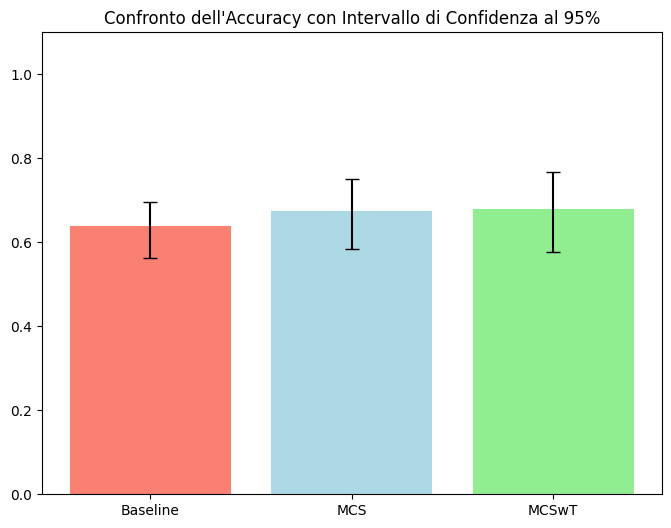

In [27]:
x_axis_tags = ["Baseline", "MCS", "MCSwT"]
y_axis_tags = [baseline_accuracy_final, mcs_accuracy_final, mcswt_accuracy_final]

lower_errors = [
    baseline_accuracy_final - baseline_accuracy_confidence_interval[0],
    mcs_accuracy_final - mcs_accuracy_confidence_interval[0],
    mcswt_accuracy_final - mcswt_accuracy_confidence_interval[0]
]
upper_errors = [
    baseline_accuracy_confidence_interval[1] - baseline_accuracy_final,
    mcs_accuracy_confidence_interval[1] - mcs_accuracy_final,
    mcswt_accuracy_confidence_interval[1] - mcswt_accuracy_final
]
asymmetric_error = [lower_errors, upper_errors]

plt.figure(figsize=(8, 6))
plt.bar(x=x_axis_tags, height=y_axis_tags, yerr=asymmetric_error, capsize=5, color=['salmon', 'lightblue', 'lightgreen'])
plt.title("Confronto dell'Accuracy con Intervallo di Confidenza al 95%")
plt.ylim(0, 1.1)
plt.savefig('/content/second-milestone/LOOCV/final-results/accuracy_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

### Macro Averaged Precision
La precision misura quanti, tra i video che il modello ha classificato come appartenenti a una classe, appartengono effettivamente a quella classe.

La Macro Averaged Precision è la media aritmetica della precision della classe del condutente e della precision di quella del passeggero.

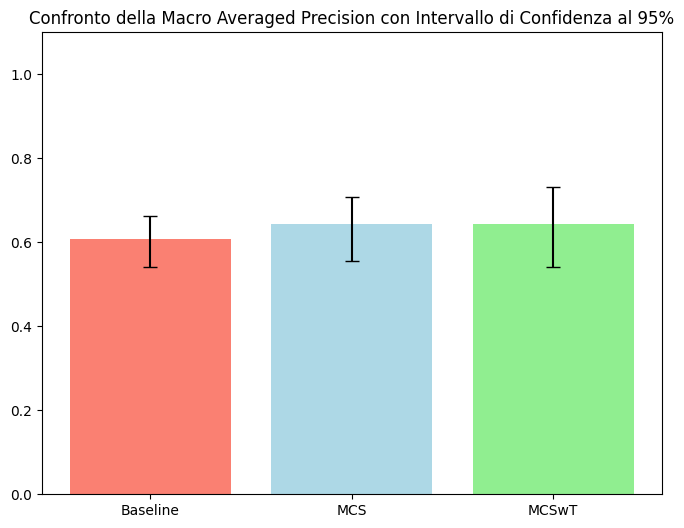

In [28]:
x_axis_tags = ["Baseline", "MCS", "MCSwT"]
y_axis_tags = [baseline_MAP_final, mcs_MAP_final, mcswt_MAP_final]

lower_errors = [
    baseline_MAP_final - baseline_MAP_confidence_interval[0],
    mcs_MAP_final - mcs_MAP_confidence_interval[0],
    mcswt_MAP_final - mcswt_MAP_confidence_interval[0]
]
upper_errors = [
    baseline_MAP_confidence_interval[1] - baseline_MAP_final,
    mcs_MAP_confidence_interval[1] - mcs_MAP_final,
    mcswt_MAP_confidence_interval[1] - mcswt_MAP_final
]
asymmetric_error = [lower_errors, upper_errors]

plt.figure(figsize=(8, 6))
plt.bar(x=x_axis_tags, height=y_axis_tags, yerr=asymmetric_error, capsize=5, color=['salmon', 'lightblue', 'lightgreen'])
plt.title("Confronto della Macro Averaged Precision con Intervallo di Confidenza al 95%")
plt.ylim(0, 1.1)
plt.savefig('/content/second-milestone/LOOCV/final-results/precision_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

### Macro Averaged Recall
La recall misura la capacità del modello di trovare tutti i video reali appartenenti a una determinata classe.

La Macro Averaged Recall è la media aritmetica del Recall del conducente e del Recall del passeggero.

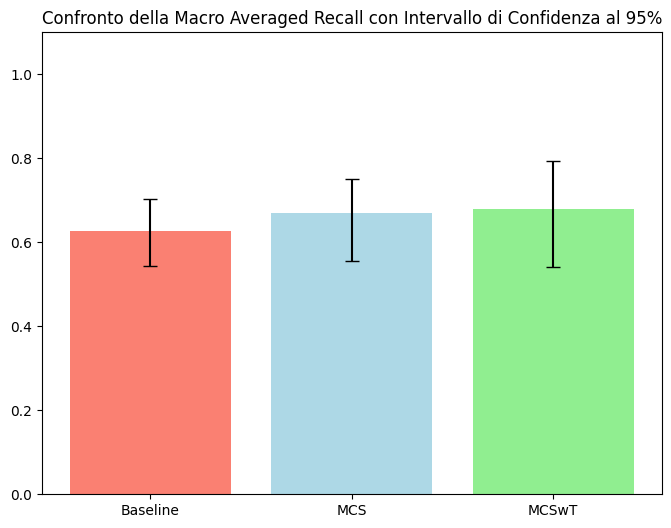

In [29]:
x_axis_tags = ["Baseline", "MCS", "MCSwT"]
y_axis_tags = [baseline_MAR_final, mcs_MAR_final, mcswt_MAR_final]

lower_errors = [
    baseline_MAR_final - baseline_MAR_confidence_interval[0],
    mcs_MAR_final - mcs_MAR_confidence_interval[0],
    mcswt_MAR_final - mcswt_MAR_confidence_interval[0]
]
upper_errors = [
    baseline_MAR_confidence_interval[1] - baseline_MAR_final,
    mcs_MAR_confidence_interval[1] - mcs_MAR_final,
    mcswt_MAR_confidence_interval[1] - mcswt_MAR_final
]
asymmetric_error = [lower_errors, upper_errors]

plt.figure(figsize=(8, 6))
plt.bar(x=x_axis_tags, height=y_axis_tags, yerr=asymmetric_error, capsize=5, color=['salmon', 'lightblue', 'lightgreen'])
plt.title("Confronto della Macro Averaged Recall con Intervallo di Confidenza al 95%")
plt.ylim(0, 1.1)
plt.savefig('/content/second-milestone/LOOCV/final-results/recall_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

### Macro Averaged F-Measure
Metrica che integra Precision e Recall.

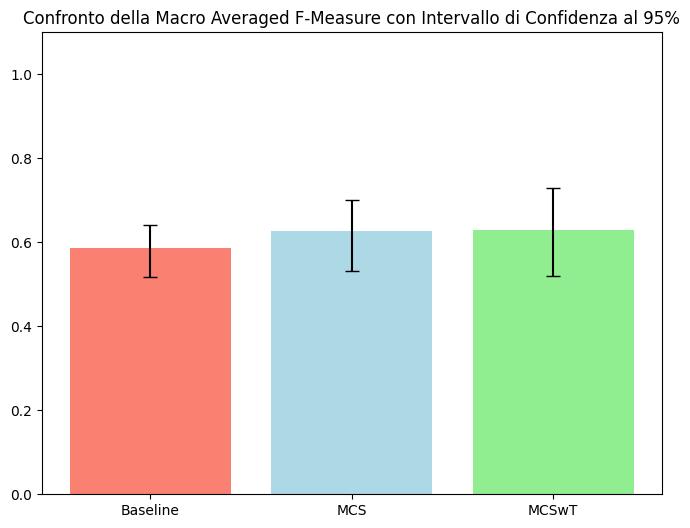

In [30]:
x_axis_tags = ["Baseline", "MCS", "MCSwT"]
y_axis_tags = [baseline_offset_or_MAF := baseline_MAF_final, mcs_MAF_final, mcswt_MAF_final]

lower_errors = [
    baseline_MAF_final - baseline_MAF_confidence_interval[0],
    mcs_MAF_final - mcs_MAF_confidence_interval[0],
    mcswt_MAF_final - mcswt_MAF_confidence_interval[0]
]
upper_errors = [
    baseline_MAF_confidence_interval[1] - baseline_MAF_final,
    mcs_MAF_confidence_interval[1] - mcs_MAF_final,
    mcswt_MAF_confidence_interval[1] - mcswt_MAF_final
]
asymmetric_error = [lower_errors, upper_errors]

plt.figure(figsize=(8, 6))
plt.bar(x=x_axis_tags, height=y_axis_tags, yerr=asymmetric_error, capsize=5, color=['salmon', 'lightblue', 'lightgreen'])
plt.title("Confronto della Macro Averaged F-Measure con Intervallo di Confidenza al 95%")
plt.ylim(0, 1.1)
plt.savefig('/content/second-milestone/LOOCV/final-results/f_measure_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## Delay medio
Il delay di uno specifico video è il numero di fotogrammi scansionati per giungere
al consenso del 80% (ovvero, tra tutte le finestre scansionate fino al raggiungimento del delay, l'80% di esse concorda sulla decisione di maggioranza corrente coerentemente con la formula del consenso interno).

Il delay di un fold è la media dei delay di tutti i video di test appartenenti al fold.

Il delay finale è semplicemente la media aritmetica dei delay medi dei fold.

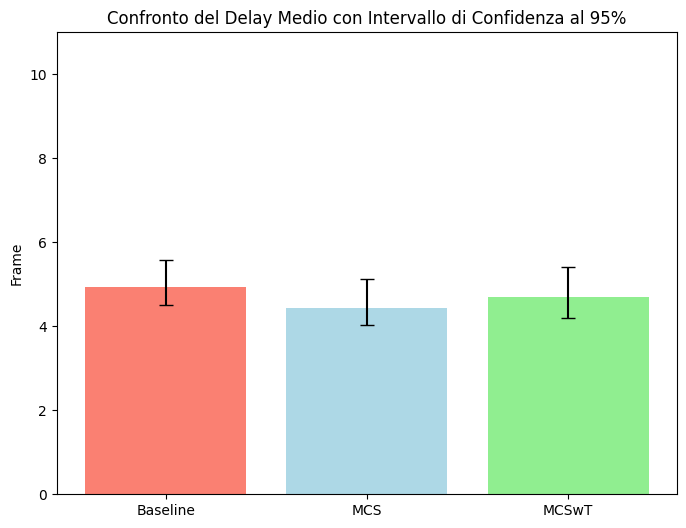

In [32]:
x_axis_tags = ["Baseline", "MCS", "MCSwT"]
y_axis_tags = [baseline_delay_avg_final, mcs_delay_avg_final, mcswt_delay_avg_final]

lower_errors = [
    baseline_delay_avg_final - baseline_delay_avg_confidence_interval[0],
    mcs_delay_avg_final - mcs_delay_avg_confidence_interval[0],
    mcswt_delay_avg_final - mcswt_delay_avg_confidence_interval[0]
]
upper_errors = [
    baseline_delay_avg_confidence_interval[1] - baseline_delay_avg_final,
    mcs_delay_avg_confidence_interval[1] - mcs_delay_avg_final,
    mcswt_delay_avg_confidence_interval[1] - mcswt_delay_avg_final
]
asymmetric_error = [lower_errors, upper_errors]

plt.figure(figsize=(8, 6))
plt.bar(x=x_axis_tags, height=y_axis_tags, yerr=asymmetric_error, capsize=5, color=['salmon', 'lightblue', 'lightgreen'])
plt.title("Confronto del Delay Medio con Intervallo di Confidenza al 95%")
plt.ylabel("Frame")
plt.ylim(0, 11)
plt.savefig('/content/second-milestone/LOOCV/final-results/delay_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## 10 - Salvataggio su Google Drive

In [33]:
drive.mount("/content/drive/")

source_dir = "/content/second-milestone/"
destination_dir = "/content/drive/MyDrive/tesi/second-milestone/"

shutil.copytree(source_dir, destination_dir)

drive.flush_and_unmount()

Mounted at /content/drive/
